# Notebook 04 — Diagnostica Modello AE (Compatta)

> **Obiettivo:** capire **perché** l'autoencoder addestrato (`ae_baseline.pth`) non separa normal da anomalo in anomaly detection.

> **Principi guida:**
> - **Read-only:** niente scrittura su `src/`, `config/`, `data/processed/` o checkpoint.
> - **Output solo a schermo:** nessun file salvato localmente.
> - **Seed fissato:** `set_seed(42)` da `src.utils.seed`.
> - **Prevalenza** sempre mostrata accanto alle AUC.
> - **Test set:** usato solo per conferma finale, mai per calibrare soglie.
> - **Forma:** ogni sezione = 1 markdown (cosa/perché/come interpretare) + 1 codice (eseguibile autonomamente).


## Sezione 0 — Setup globale

**Cosa:** carica config, dati processati, loader, modello dal checkpoint `ae_baseline.pth`, device, prevalenza.
**Perché:** tutte le sezioni successive dipendono da queste variabili.
**Come interpretare:** il modello caricato è esattamente quello salvato nel checkpoint, senza modifiche o filtri.

In [37]:
"""Sezione 0 — Setup globale: carica config, dati, modello, loader."""
try:
    SEED
except NameError:
    SEED = 42

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# --- Moduli di progetto ---
from src.utils.seed import set_seed
set_seed(SEED)
from src.utils.config import load_config, get_param
from src.data.dataset import build_loader
from src.models.autoencoder import SequenceAutoencoder

config = load_config()
processed_dir = Path(PROJECT_ROOT) / "data" / "processed"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Carica dati processati (nomi reali prodotti da notebook 02) ---
normal_arr = np.load(processed_dir / "normal_scaled.npy")
slow_arr = np.load(processed_dir / "slow_scaled.npy")

# Split dei dati per split (train/val/test da normal, val/test da slow)
train_data = normal_arr
val_normal_data = normal_arr
val_anomaly_data = slow_arr
test_normal_data = normal_arr
test_anomaly_data = slow_arr

# Carica i piani di partizione (window start indices per ogni split)
train_starts_arr = np.load(processed_dir / "plan_train.npy")
val_normal_starts_arr = np.load(processed_dir / "plan_val_normal.npy")
val_anomaly_starts_arr = np.load(processed_dir / "plan_val_anomaly.npy")
test_normal_starts_arr = np.load(processed_dir / "plan_test_normal.npy")
test_anomaly_starts_arr = np.load(processed_dir / "plan_test_anomaly.npy")

selected_cols = np.load(processed_dir / "selected_columns.npy", allow_pickle=True)
feature_names = [str(c) for c in selected_cols]

# --- Carica checkpoint per ricavare i veri parametri del modello ---
ckpt_path = Path(PROJECT_ROOT) / "reports" / "checkpoints" / "ae_baseline.pth"
ckpt = torch.load(ckpt_path, map_location="cpu")
ckpt_sd = ckpt["model_state_dict"]

# Latent dim dal checkpoint (shape di encoder.net.8.weight: [latent_dim, 16, 1])
latent_dim = ckpt_sd["encoder.net.8.weight"].shape[0]
W = int(get_param(config, "model.window_size", 16))
batch_size = int(get_param(config, "training.batch_size", 256))
input_dim = int(get_param(config, "model.input_dim", 86))

# DataLoader
train_loader = build_loader(train_data, train_starts_arr, window_size=W,
                            batch_size=batch_size, label=0, shuffle=True, num_workers=0)
val_normal_loader = build_loader(val_normal_data, val_normal_starts_arr, window_size=W,
                                 batch_size=batch_size, label=0, num_workers=0)
val_anomaly_loader = build_loader(val_anomaly_data, val_anomaly_starts_arr, window_size=W,
                                  batch_size=batch_size, label=1, num_workers=0)
test_normal_loader = build_loader(test_normal_data, test_normal_starts_arr, window_size=W,
                                  batch_size=batch_size, label=0, num_workers=0)
test_anomaly_loader = build_loader(test_anomaly_data, test_anomaly_starts_arr, window_size=W,
                                   batch_size=batch_size, label=1, num_workers=0)

# Crea modello con latent_dim del checkpoint e carica pesi
model = SequenceAutoencoder(input_dim=input_dim, window_size=W, latent_dim=latent_dim)
model.load_state_dict(ckpt_sd, strict=True)
print("Modello caricato da %s (latent_dim=%d, W=%d)" % (ckpt_path, latent_dim, W))
model.to(DEVICE)
model.eval()

# --- Prevalenza ---
train_len = len(train_data)
val_normal_len = len(val_normal_data)
val_anomaly_len = len(val_anomaly_data)
test_normal_len = len(test_normal_data)
test_anomaly_len = len(test_anomaly_data)

val_prev = val_anomaly_len / (val_normal_len + val_anomaly_len)
test_prev = test_anomaly_len / (test_normal_len + test_anomaly_len)
val_prevalence = val_prev
test_prevalence = test_prev

print("SETUP GLOBALE completato.")
print("  input_dim=%d, W=%d, latent_dim=%d" % (input_dim, W, latent_dim))
print("  train_data=%d, val_normal_data=%d, val_anomaly_data=%d, test_normal_data=%d, test_anomaly_data=%d" % (train_len, val_normal_len, val_anomaly_len, test_normal_len, test_anomaly_len))
print("  train_windows=%d, val_normal_windows=%d, val_anomaly_windows=%d, test_normal_windows=%d, test_anomaly_windows=%d" % (len(train_starts_arr), len(val_normal_starts_arr), len(val_anomaly_starts_arr), len(test_normal_starts_arr), len(test_anomaly_starts_arr)))
print("  device=%s" % DEVICE)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\ungol\\OneDrive\\Desktop\\Ing-Inf-PoliTo\\secondo anno\\secondo semestre\\Machine Learning in Application\\project\\AM01\\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\\data\\processed\\normal_scaled.npy'

## Sezione 1 — Baseline MAE_zero vs MAE_AE

**Cosa:** confronta l'errore MAE dell'autoencoder con quello di un baseline che predice sempre la media per-canale del train (MAE_zero).
**Perché:** se MAE_AE ≈ MAE_zero l'autoencoder non impara; se MAE_AE ≪ MAE_zero impara a ricostruire.
**Come interpretare:** ratio MAE_AE/MAE_zero > 0.8 → underfitting; AUC direct ≈ 0.5 e inverted > 0.5 → errore invertito (anomalie ricostruite meglio).

In [ ]:
"""Sezione 1 — Baseline MAE_zero vs MAE_AE."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Compute per-channel mean from train ---
train_flat = train_data
channel_means = train_flat.mean(axis=0)
print("Media per-canale del train: shape=%s" % str(channel_means.shape))
print("Max |media|: %.6e (dovrebbe ≈ 0 su dati standardizzati)" % np.abs(channel_means).max())

# --- MAE_ZERO: mean per-channel error if we predict channel_means ---
def compute_mae_zero(loader, channel_means, device=DEVICE):
    errors = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device)
        x_pred = np.broadcast_to(channel_means, x.shape)
        x_np = x.cpu().numpy()
        mae_per_window = np.abs(x_np - x_pred).mean(axis=(1, 2))
        errors.append(mae_per_window)
    return np.concatenate(errors)

print("\nCalcolo MAE_zero...")
mae_zero_train = compute_mae_zero(train_loader, channel_means)
mae_zero_val_normal = compute_mae_zero(val_normal_loader, channel_means)
mae_zero_val_anomaly = compute_mae_zero(val_anomaly_loader, channel_means)

print("  MAE_zero_train:        mean=%.6f" % mae_zero_train.mean())
print("  MAE_zero_val_normal:   mean=%.6f" % mae_zero_val_normal.mean())
print("  MAE_zero_val_anomaly:  mean=%.6f" % mae_zero_val_anomaly.mean())

# --- MAE_AE: real MAE from autoencoder ---
def compute_errors_from_loader(model, loader, device, metric="mae"):
    """Compute per-sample reconstruction error from a DataLoader."""
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            err = model.compute_reconstruction_error(x, reduction="sample", metric=metric)
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)

mae_ae_train = compute_errors_from_loader(model, train_loader, DEVICE, metric="mae")
mae_ae_val_normal = compute_errors_from_loader(model, val_normal_loader, DEVICE, metric="mae")
mae_ae_val_anomaly = compute_errors_from_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("\n  MAE_AE_train:          mean=%.6f" % mae_ae_train.mean())
print("  MAE_AE_val_normal:     mean=%.6f" % mae_ae_val_normal.mean())
print("  MAE_AE_val_anomaly:    mean=%.6f" % mae_ae_val_anomaly.mean())

# --- Ratios ---
ratio_val_normal = mae_ae_val_normal.mean() / mae_zero_val_normal.mean()
ratio_val_anomaly = mae_ae_val_anomaly.mean() / mae_zero_val_anomaly.mean()
print("\n  Ratio MAE_AE/MAE_zero (val_normal):  %.4f" % ratio_val_normal)
print("  Ratio MAE_AE/MAE_zero (val_anomaly): %.4f" % ratio_val_anomaly)

# --- AUC comparison ---
from sklearn.metrics import roc_auc_score
from src.evaluation.metrics import calculate_auc

val_labels = np.concatenate([np.zeros(len(mae_ae_val_normal)), np.ones(len(mae_ae_val_anomaly))])
err_combined = np.concatenate([mae_ae_val_normal, mae_ae_val_anomaly])
auc_ae = calculate_auc(val_labels, err_combined)

mae_zero_combined = np.concatenate([mae_zero_val_normal, mae_zero_val_anomaly])
auc_zero = calculate_auc(val_labels, mae_zero_combined)

auc_ae_inv = calculate_auc(val_labels, -err_combined)
auc_zero_inv = calculate_auc(val_labels, -mae_zero_combined)

print("\n--- AUC VALIDATION (prevalenza=%.4f) ---" % val_prevalence)
print("  AE MAE (direct):      ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_ae['roc_auc'], auc_ae['pr_auc']))
print("  AE MAE (inverted):    ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_ae_inv['roc_auc'], auc_ae_inv['pr_auc']))
print("  Zero MAE (direct):    ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_zero['roc_auc'], auc_zero['pr_auc']))
print("  Zero MAE (inverted):  ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_zero_inv['roc_auc'], auc_zero_inv['pr_auc']))

# Interpretazione
print("\n--- Interpretazione ---")
if ratio_val_anomaly > 0.8:
    print("  → Ratio > 0.8: AE NON impara (underfitting). MAE_AE ≈ MAE_zero.")
elif ratio_val_anomaly < 0.3:
    print("  → Ratio < 0.3: AE impara a ricostruire (MAE_AE ≪ MAE_zero).")
    if auc_ae_inv['roc_auc'] > 0.65:
        print("  → AUC inverted > 0.65: segno invertito (errore basso = anomalo).")
    elif auc_ae['roc_auc'] > 0.55:
        print("  → AUC direct > 0.55: errore alto = anomalo (discriminativo).")
    else:
        print("  → AUC ≈ 0.5 (direct e inverted): AE impara ma ampiezza non separa classi.")
else:
    print("  → Ratio 0.3-0.8: AE impara parzialmente.")

Media per-canale del train: shape=(86,)
Max |media|: 1.000000e+00 (dovrebbe ≈ 0 su dati standardizzati)

Calcolo MAE_zero...
  MAE_zero_train:        mean=0.207048
  MAE_zero_val_normal:   mean=0.206385
  MAE_zero_val_anomaly:  mean=0.197735

  MAE_AE_train:          mean=0.063344
  MAE_AE_val_normal:     mean=0.065846
  MAE_AE_val_anomaly:    mean=0.097477

  Ratio MAE_AE/MAE_zero (val_normal):  0.3190
  Ratio MAE_AE/MAE_zero (val_anomaly): 0.4930

--- AUC VALIDATION (prevalenza=0.1509) ---
  AE MAE (direct):      ROC-AUC=0.8278, PR-AUC=0.7831
  AE MAE (inverted):    ROC-AUC=0.1722, PR-AUC=0.2379
  Zero MAE (direct):    ROC-AUC=0.4220, PR-AUC=0.3140
  Zero MAE (inverted):  ROC-AUC=0.5780, PR-AUC=0.4293

--- Interpretazione ---
  → Ratio 0.3-0.8: AE impara parzialmente.


## Sezione 2 — Errore per canale

**Cosa:** calcola MAE per canale su val_normal e val_anomaly usando compute_reconstruction_error(reduction='none').
**Perché:** vede quali canali separano normal da anomalo e se le anomalie hanno errore più alto o più basso (errore invertito).
**Come interpretare:** se alcune feature hanno MAE su anomalie più basso che su normal → errore invertito (AE ricostruisce meglio le anomalie).

In [ ]:
"""Sezione 2 — Errore per canale."""
try:
    SEED
except NameError:
    SEED = 42
from src.utils.seed import set_seed
set_seed(SEED)

# --- Errore per canale su val (usa model.forward direttamente) ---
def channel_errors_from_loader(loader, model, device):
    model.eval()
    all_errs = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)  # forward gestisce (B, W, input_dim) → (B, W, input_dim)
            diff = torch.abs(x - x_pred)  # (B, W, input_dim)
            all_errs.append(diff.cpu().numpy())
    return np.concatenate(all_errs, axis=0)  # (n, W, input_dim)

val_norm_err = channel_errors_from_loader(val_normal_loader, model, DEVICE)
val_anom_err = channel_errors_from_loader(val_anomaly_loader, model, DEVICE)

# val_norm_err: (n_norm, W, input_dim) ; val_anom_err: (n_anom, W, input_dim)
channel_norm_err = val_norm_err.mean(axis=(0, 1))
channel_anom_err = val_anom_err.mean(axis=(0, 1))

print("=== ERRORE PER CANALE (val set) ===")
print("%-30s %12s %12s %12s %10s" % ("Feature", "MAE_norm", "MAE_anom", "Diff", "Ratio"))
for i, name in enumerate(feature_names[:input_dim]):
    n = channel_norm_err[i]
    a = channel_anom_err[i]
    diff = a - n
    ratio = a / (n + 1e-12)
    marker = " <-- INVERTITO" if a < n else ""
    print("%-30s %12.6f %12.6f %12.6f %10.3f%s" % (str(name)[:28], n, a, diff, ratio, marker))

# --- Top canali più discriminanti ---
diff_arr = channel_anom_err - channel_norm_err
top_norm = np.argsort(diff_arr)[::-1][:10]  # anomalo molto più alto
top_anom = np.argsort(diff_arr)[:10]  # anomalo molto più basso (invertito)

print("\n--- TOP 10 CANALI: anomalia ha errore più ALTO ---")
for i in top_norm:
    print("  %s: norm=%.6f anom=%.6f diff=%.6f" % (feature_names[i][:40], channel_norm_err[i], channel_anom_err[i], diff_arr[i]))

print("\n--- TOP 10 CANALI: anomalia ha errore più BASSO (invertito) ---")
for i in top_anom:
    print("  %s: norm=%.6f anom=%.6f diff=%.6f" % (feature_names[i][:40], channel_norm_err[i], channel_anom_err[i], diff_arr[i]))


=== ERRORE PER CANALE (val set) ===
Feature                            MAE_norm     MAE_anom         Diff      Ratio
action                             0.436244     0.465998     0.029753      1.068
machine_nameKuka Robot_appar       0.072179     0.061717    -0.010462      0.855 <-- INVERTITO
machine_nameKuka Robot_curre       0.109923     0.095280    -0.014643      0.867 <-- INVERTITO
machine_nameKuka Robot_frequ       0.189443     0.228908     0.039465      1.208
machine_nameKuka Robot_phase       0.062661     0.062702     0.000041      1.001
machine_nameKuka Robot_power       0.071602     0.060087    -0.011515      0.839 <-- INVERTITO
machine_nameKuka Robot_power       0.058231     0.062508     0.004277      1.073
machine_nameKuka Robot_react       0.089191     0.092462     0.003271      1.037
machine_nameKuka Robot_volta       0.200844     0.264128     0.063283      1.315
sensor_id1_AccX                    0.008005     0.005853    -0.002152      0.731 <-- INVERTITO
sensor_id1_AccY  

## Sezione 3 — Distribuzioni Errore + Separabilità

**Cosa:** istogrammi MAE per finestra su val_normal vs val_anomaly, test KS, overlap coefficient, confronto media/mediana.
**Perché:** verifica separabilità delle distribuzioni e quale classe viene ricostruita meglio (errore invertito).
**Come interpretare:**
- Picchi sovrapposti + overlap alto + KS p-value > 0.05 → scarsa separabilità
- Anomalia media < Normale → errore invertito (AE ricostruisce meglio anomalie)
- Test KS significativo + overlap basso → distribuzioni separabili, threshold può funzionare

=== DISTRIBUZIONI ERRORE + SEPARABILITÀ (val set) ===
val_normal:   mean=0.065846 median=0.065589 std=0.020133
val_anomaly:  mean=0.097477 median=0.100346 std=0.025704
Overlap range: norm_max=0.131743 anom_min=0.034255

✓ NORMAL ricostruito meglio (media MAE minore di 0.031630)
  → AE ricostruisce meglio i normali → errore può discriminare con soglia corretta

Test KS (distribuzioni diverse): statistic=0.5329, p-value=0.00e+00
  → Distribuzioni significativamente diverse (separabili)
Overlap coefficient: 0.5035 (0=separati, 1=identici)


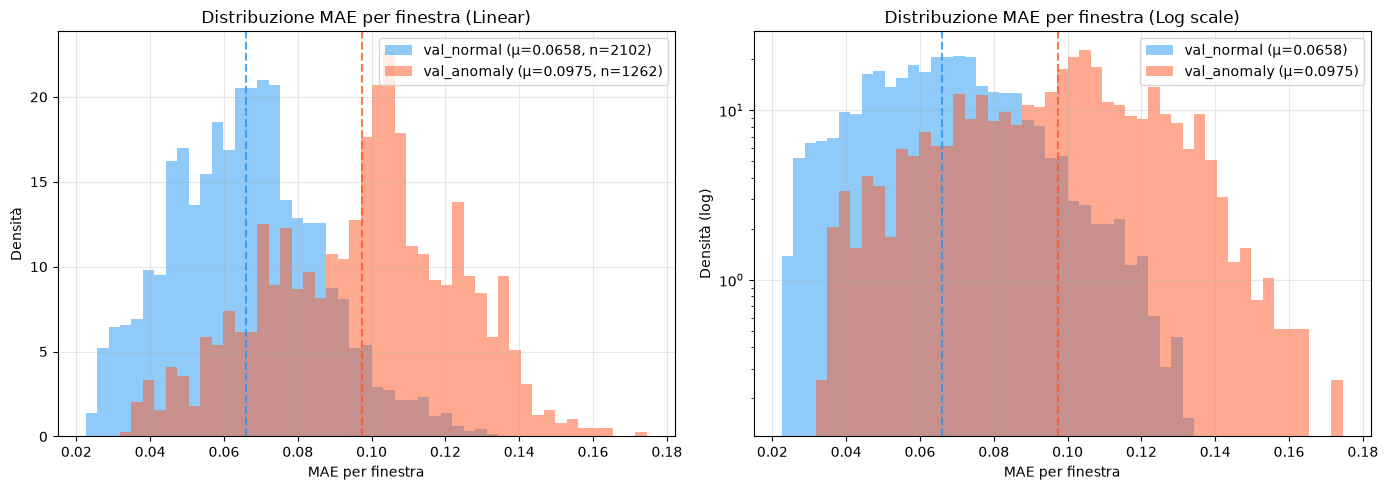

In [ ]:
"""Sezione 3 — Distribuzioni Errore + Separabilità."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ks_2samp

# --- Errore MAE per finestra ---
err_val_norm = compute_errors_from_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anom = compute_errors_from_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("=== DISTRIBUZIONI ERRORE + SEPARABILITÀ (val set) ===")
print("val_normal:   mean=%.6f median=%.6f std=%.6f" % (err_val_norm.mean(), np.median(err_val_norm), err_val_norm.std()))
print("val_anomaly:  mean=%.6f median=%.6f std=%.6f" % (err_val_anom.mean(), np.median(err_val_anom), err_val_anom.std()))
print("Overlap range: norm_max=%.6f anom_min=%.6f" % (err_val_norm.max(), err_val_anom.min()))

# --- Quale classe viene ricostruita meglio? ---
if err_val_norm.mean() < err_val_anom.mean():
    diff = err_val_anom.mean() - err_val_norm.mean()
    print(f"\n✓ NORMAL ricostruito meglio (media MAE minore di {diff:.6f})")
    print("  → AE ricostruisce meglio i normali → errore può discriminare con soglia corretta")
else:
    diff = err_val_norm.mean() - err_val_anom.mean()
    print(f"\n⚠ ANOMALY ricostruito meglio (media MAE minore di {diff:.6f})")
    print("  → AE 'preferisce' anomalie → errore NON discrimina correttamente")

# --- Test KS per separabilità ---
ks_stat, ks_p = ks_2samp(err_val_norm, err_val_anom)
print(f"\nTest KS (distribuzioni diverse): statistic={ks_stat:.4f}, p-value={ks_p:.2e}")
if ks_p < 0.05:
    print("  → Distribuzioni significativamente diverse (separabili)")
else:
    print("  → Distribuzioni NON significativamente diverse (poco separabili)")

# --- Overlap coefficient (area comune) ---
hist_norm, bins = np.histogram(err_val_norm, bins=50, density=True)
hist_anom, _ = np.histogram(err_val_anom, bins=bins, density=True)
overlap = np.sum(np.minimum(hist_norm, hist_anom)) * (bins[1] - bins[0])
print(f"Overlap coefficient: {overlap:.4f} (0=separati, 1=identici)")

# --- Plot: Istogramma sovrapposto (linear + log) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bins_shared = np.linspace(min(err_val_norm.min(), err_val_anom.min()),
                          max(err_val_norm.max(), err_val_anom.max()), 50)

# Sinistra: linear scale
ax = axes[0]
ax.hist(err_val_norm, bins=bins_shared, alpha=0.5, color="#2196F3", 
        label=f'val_normal (μ={err_val_norm.mean():.4f}, n={len(err_val_norm):.0f})', density=True)
ax.hist(err_val_anom, bins=bins_shared, alpha=0.5, color="#FF5722", 
        label=f'val_anomaly (μ={err_val_anom.mean():.4f}, n={len(err_val_anom):.0f})', density=True)
ax.axvline(err_val_norm.mean(), color="#2196F3", linestyle="--", alpha=0.8)
ax.axvline(err_val_anom.mean(), color="#FF5722", linestyle="--", alpha=0.8)
ax.set_xlabel("MAE per finestra")
ax.set_ylabel("Densità")
ax.set_title("Distribuzione MAE per finestra (Linear)")
ax.legend()
ax.grid(True, alpha=0.3)

# Destra: log scale
ax = axes[1]
ax.hist(err_val_norm, bins=bins_shared, alpha=0.5, color="#2196F3", 
        label=f'val_normal (μ={err_val_norm.mean():.4f})', density=True)
ax.hist(err_val_anom, bins=bins_shared, alpha=0.5, color="#FF5722", 
        label=f'val_anomaly (μ={err_val_anom.mean():.4f})', density=True)
ax.axvline(err_val_norm.mean(), color="#2196F3", linestyle="--", alpha=0.8)
ax.axvline(err_val_anom.mean(), color="#FF5722", linestyle="--", alpha=0.8)
ax.set_yscale("log")
ax.set_xlabel("MAE per finestra")
ax.set_ylabel("Densità (log)")
ax.set_title("Distribuzione MAE per finestra (Log scale)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Sezione 3B — Ricostruzione per-Finestra (Dettaglio)

**Cosa:** mostra input vs ricostruzione con heatmap errore per canale × timestep su 5 finestre normali e 5 anomalie (stratificate per errore: basso/medio/alto).
**Perché:** permette di vedere *cosa* il modello impara a ricostruire e se le anomalie slow-motion vengono ricostruite diversamente nel tempo.
**Come interpretare:**
- Heatmap uniforme → il modello ignora le anomalie (collasso)
- Errori concentrati su pochi canali/timestep → il modello cattura pattern specifici
- Anomalie con errore simile ai normali → nessuna separazione visiva

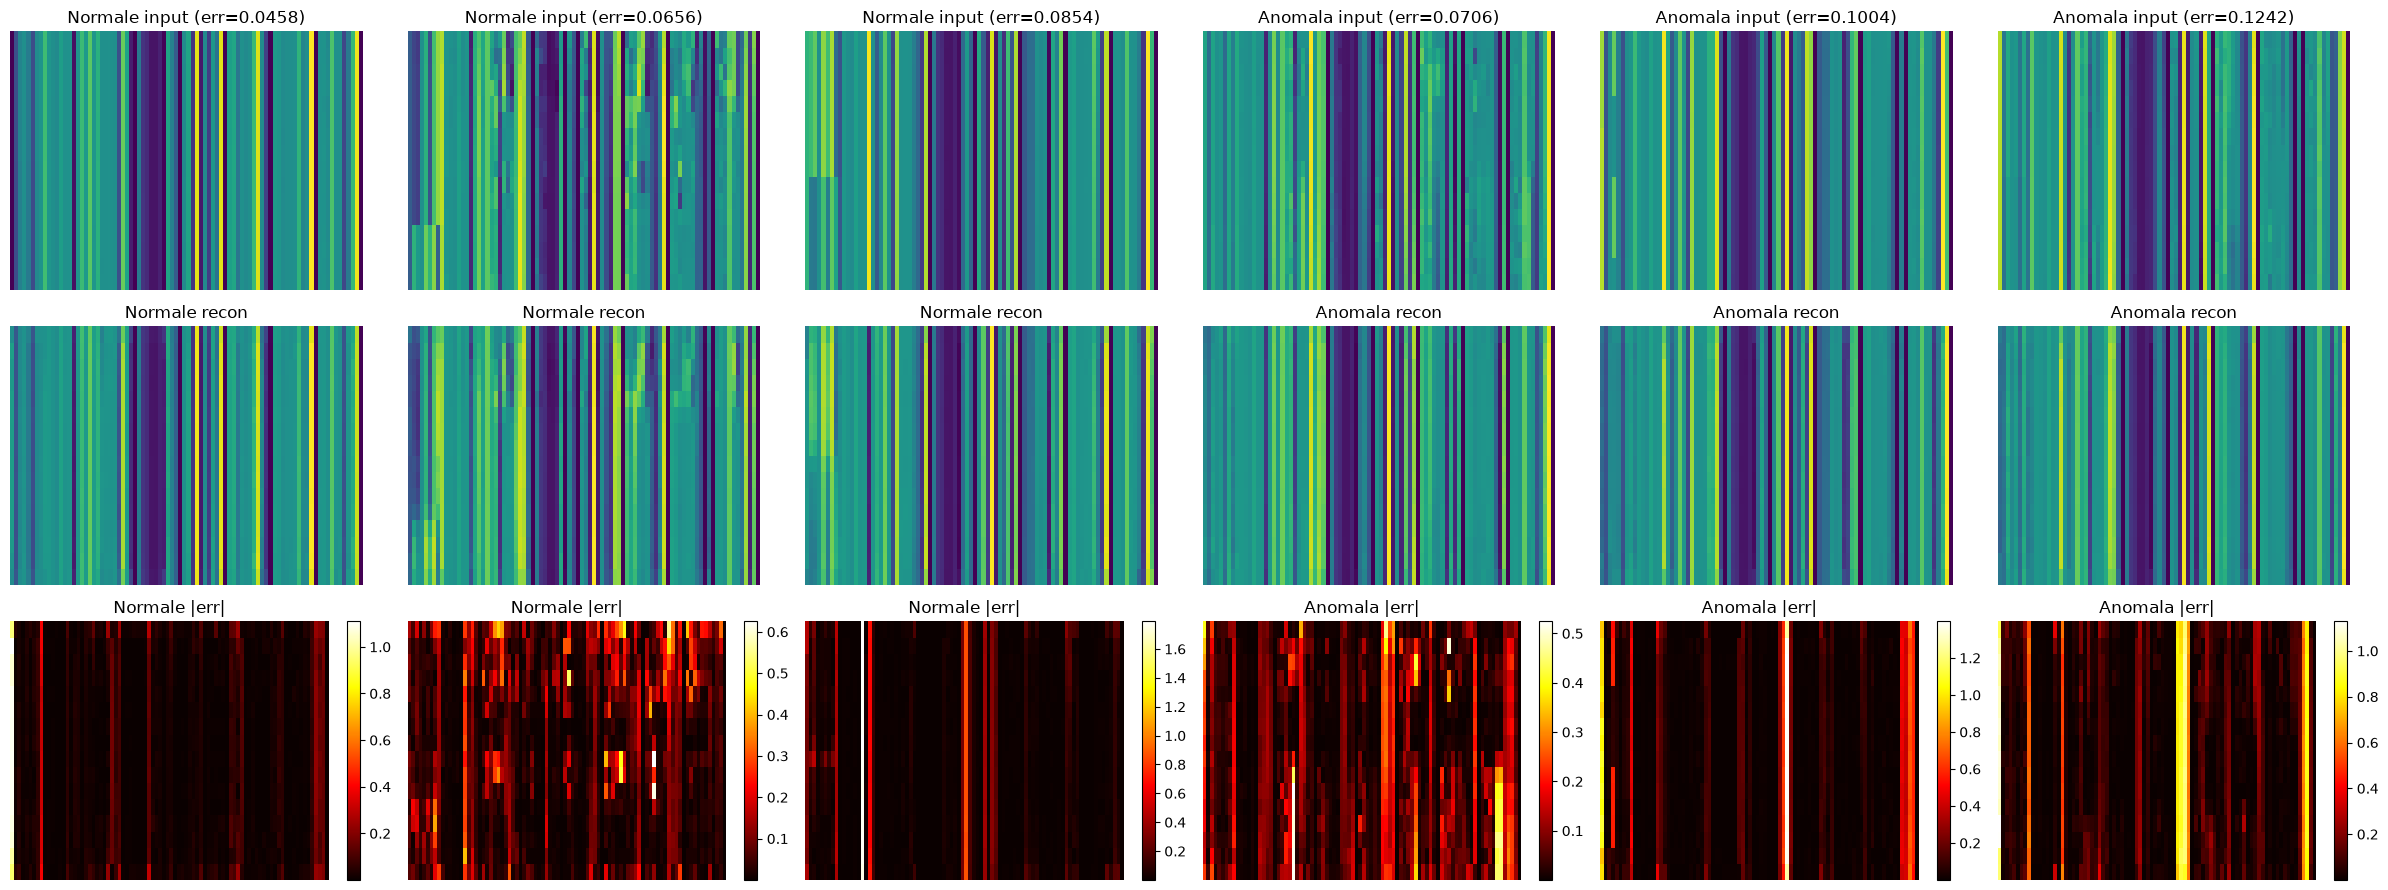

=== RIEPILOGO RICOSTRUZIONE PER-FINESTRA ===
Normale: errore medio=0.065581, min=0.045778, max=0.085376
Anomala: errore medio=0.098375, min=0.070580, max=0.124175


In [ ]:
"""Sezione 3B — Ricostruzione per-Finestra (Dettaglio)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
import torch

# --- Seleziona finestre rappresentative per errore (basso/medio/alto) ---
def select_representative_windows(dataset, model, device, n_per_tier=3):
    model.eval()
    windows = []
    errors = []
    for i in range(len(dataset)):
        x = dataset[i][0].unsqueeze(0).to(device)
        with torch.no_grad():
            x_pred = model(x)
        err = torch.abs(x - x_pred).mean(dim=(1, 2)).item()
        windows.append(dataset[i][0])
        errors.append(err)
    windows = torch.stack(windows)
    errors = np.array(errors)
    tiers = np.array_split(np.argsort(errors), 3)
    selected = []
    for tier in tiers:
        idx = tier[len(tier) // 2]  # mediana del tier
        selected.append((windows[idx], errors[idx]))
    return selected[:n_per_tier * 3]

sel_norm = select_representative_windows(val_normal_loader.dataset, model, DEVICE)
sel_anom = select_representative_windows(val_anomaly_loader.dataset, model, DEVICE)

# --- Plot: input / reconstruction / heatmap errore ---
n_rows = 3  # input, recon, errore
n_cols = len(sel_norm) + len(sel_anom)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
if n_cols == 1:
    axes = axes.reshape(-1, 1)

col = 0
for label, sel in [("Normale", sel_norm), ("Anomala", sel_anom)]:
    for x_win, err_win in sel:
        x_win_b = x_win.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            x_pred = model(x_win_b)
        err_map = torch.abs(x_win_b - x_pred).cpu().numpy()[0]  # (C, W)

        # Riga 0: input
        axes[0, col].imshow(x_win.cpu().numpy(), aspect='auto', cmap='viridis')
        axes[0, col].set_title(f"{label} input (err={err_win:.4f})")
        axes[0, col].axis('off')

        # Riga 1: ricostruzione
        axes[1, col].imshow(x_pred[0].cpu().detach().numpy(), aspect='auto', cmap='viridis')
        axes[1, col].set_title(f"{label} recon")
        axes[1, col].axis('off')

        # Riga 2: heatmap errore
        im = axes[2, col].imshow(err_map, aspect='auto', cmap='hot')
        axes[2, col].set_title(f"{label} |err|")
        axes[2, col].axis('off')
        plt.colorbar(im, ax=axes[2, col], fraction=0.046)

        col += 1

plt.tight_layout()
plt.show()

# --- Statistiche riepilogo ---
print("=== RIEPILOGO RICOSTRUZIONE PER-FINESTRA ===")
for label, sel in [("Normale", sel_norm), ("Anomala", sel_anom)]:
    errs = [e for _, e in sel]
    print(f"{label}: errore medio={np.mean(errs):.6f}, min={np.min(errs):.6f}, max={np.max(errs):.6f}")

## Sezione 3C — Errore per Timestep dentro la Finestra

**Cosa:** traccia l'errore MAE medio per timestep (0..W-1) separato per normali e anomalie.
**Perché:** le anomalie slow-motion potrebbero avere un errore che cresce o decresce dentro la finestra; questa curva rivela se il modello le cattura all'inizio o solo alla fine.
**Come interpretare:**
- Curva anomaly sopra quella normal → anomalie ricostruite peggio (corretto per AD)
- Curva sotto → errore invertito (anomalie ricostruite meglio)
- Divergenza crescente col tempo → anomalia lenta non catturata all'inizio

=== ERRORE PER TIMESTEP (Validation) ===
t=  0: norm=0.082779±0.036659, anom=0.106995±0.031721
t=  4: norm=0.062147±0.027398, anom=0.095263±0.028953
t=  8: norm=0.061470±0.026994, anom=0.095905±0.029054
t= 12: norm=0.064044±0.028698, anom=0.095481±0.028196
t= 15: norm=0.083457±0.037487, anom=0.107737±0.031679


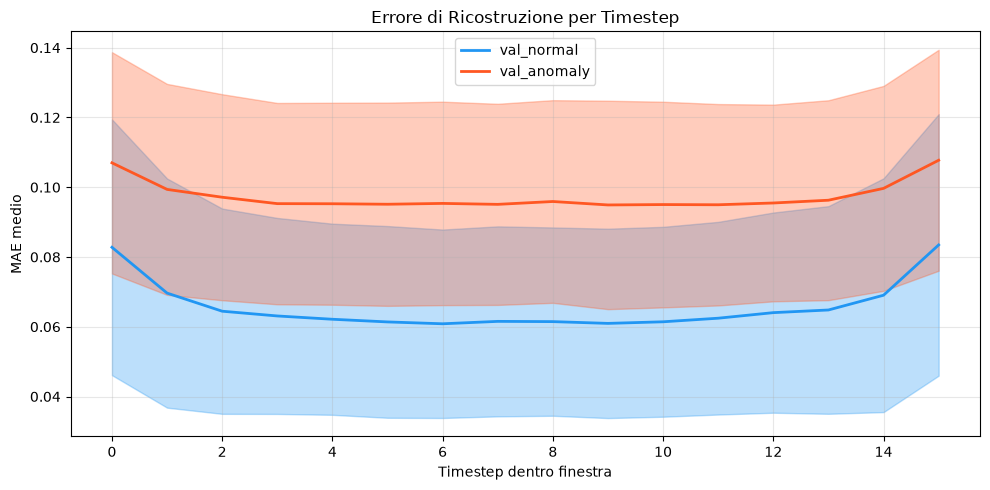


Differenza media anom - norm: 0.031630
Differenza al primo timestep (t=0): 0.024216
Differenza all'ultimo timestep (t=15): 0.024280
→ L'errore anomalia cresce dentro la finestra (slow-motion non catturato all'inizio)


In [ ]:
"""Sezione 3C — Errore per Timestep dentro la Finestra."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
import torch

# --- Calcola errore per timestep ---
def err_per_timestep(loader, model, device):
    model.eval()
    all_errs = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)
            err = torch.abs(x - x_pred).mean(dim=2)  # (B, W) errore per timestep
            all_errs.append(err.cpu().numpy())
    return np.concatenate(all_errs, axis=0)  # (n, W)

err_t_norm = err_per_timestep(val_normal_loader, model, DEVICE)
err_t_anom = err_per_timestep(val_anomaly_loader, model, DEVICE)

mean_norm = err_t_norm.mean(axis=0)  # (W,)
mean_anom = err_t_anom.mean(axis=0)
std_norm = err_t_norm.std(axis=0)
std_anom = err_t_anom.std(axis=0)

print("=== ERRORE PER TIMESTEP (Validation) ===")
for t in [0, W//4, W//2, 3*W//4, W-1]:
    print(f"t={t:3d}: norm={mean_norm[t]:.6f}±{std_norm[t]:.6f}, anom={mean_anom[t]:.6f}±{std_anom[t]:.6f}")

# --- Plot ---
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
t = np.arange(W)
ax.plot(t, mean_norm, color="#2196F3", linewidth=2, label="val_normal")
ax.fill_between(t, mean_norm - std_norm, mean_norm + std_norm, color="#2196F3", alpha=0.3)
ax.plot(t, mean_anom, color="#FF5722", linewidth=2, label="val_anomaly")
ax.fill_between(t, mean_anom - std_anom, mean_anom + std_anom, color="#FF5722", alpha=0.3)
ax.set_xlabel("Timestep dentro finestra")
ax.set_ylabel("MAE medio")
ax.set_title("Errore di Ricostruzione per Timestep")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Differenza anomaly - normal per timestep ---
diff_t = mean_anom - mean_norm
print(f"\nDifferenza media anom - norm: {diff_t.mean():.6f}")
print(f"Differenza al primo timestep (t=0): {diff_t[0]:.6f}")
print(f"Differenza all'ultimo timestep (t={W-1}): {diff_t[-1]:.6f}")
if diff_t[-1] > diff_t[0]:
    print("→ L'errore anomalia cresce dentro la finestra (slow-motion non catturato all'inizio)")
elif diff_t[-1] < diff_t[0]:
    print("→ L'errore anomalia diminuisce dentro la finestra")
else:
    print("→ Errore costante dentro la finestra")

## Sezione 4 — Drift temporale val vs test

**Cosa:** confronta distribuzioni errore su test_normal vs test_anomaly e le confronta con val.
**Perché:** il mismatch val vs test dipende dal fatto che i dati temporali sono distribuiti diversamente.
**Come interpretare:** se le distribuzioni test si allontanano da val, il threshold calibrato su val è inaffidabile su test.

In [ ]:
"""Sezione 4 — Drift temporale val vs test."""
try:
    SEED
except NameError:
    SEED = 42
from src.utils.seed import set_seed
set_seed(SEED)

# --- Errore su test ---
err_test_norm = compute_errors_from_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anom = compute_errors_from_loader(model, test_anomaly_loader, DEVICE, metric="mae")

print("=== DRIFT TEMPORALE: VAL vs TEST ===")
print("val_normal:   mean=%.6f median=%.6f" % (err_val_norm.mean(), np.median(err_val_norm)))
print("val_anomaly:  mean=%.6f median=%.6f" % (err_val_anom.mean(), np.median(err_val_anom)))
print("test_normal:  mean=%.6f median=%.6f" % (err_test_norm.mean(), np.median(err_test_norm)))
print("test_anomaly: mean=%.6f median=%.6f" % (err_test_anom.mean(), np.median(err_test_anom)))

print("\nDelta mediane: val anom - val norm = %.6f" % (np.median(err_val_anom) - np.median(err_val_norm)))
print("Delta mediane: test anom - test norm = %.6f" % (np.median(err_test_anom) - np.median(err_test_norm)))

print("\nPrevalenza validation: %.4f" % val_prevalence)
print("Prevalenza test:       %.4f" % test_prevalence)

=== DRIFT TEMPORALE: VAL vs TEST ===
val_normal:   mean=0.065846 median=0.065589
val_anomaly:  mean=0.097477 median=0.100346
test_normal:  mean=0.067321 median=0.066948
test_anomaly: mean=0.097233 median=0.100664

Delta mediane: val anom - val norm = 0.034757
Delta mediane: test anom - test norm = 0.033716

Prevalenza validation: 0.1509
Prevalenza test:       0.1509


## Sezione 5 — Test overfitting

**Cosa:** confronta errore MAE su train vs validation per capire se il modello overfitta o underfitta.
**Perché:** se train error ≪ val error il modello overfitta; se train ≈ val e entrambi alti, underfitta.
**Come interpretare:** gap train-val ampio → overfitting; entrambi alti e vicini → underfitting.

In [ ]:
"""Sezione 5 — Test overfitting."""
try:
    SEED
except NameError:
    SEED = 42
from src.utils.seed import set_seed
set_seed(SEED)

# --- Errore su train ---
err_train = compute_errors_from_loader(model, train_loader, DEVICE, metric="mae")

print("=== TEST OVERFITTING ===")
print("train:   mean=%.6f median=%.6f" % (err_train.mean(), np.median(err_train)))
print("val_norm: mean=%.6f median=%.6f" % (err_val_norm.mean(), np.median(err_val_norm)))
print("Gap train-val_norm: %.6f" % (err_val_norm.mean() - err_train.mean()))
print("Ratio val_norm/train: %.3f" % (err_val_norm.mean() / (err_train.mean() + 1e-12)))

if err_val_norm.mean() / (err_train.mean() + 1e-12) > 1.5:
    print("→ Overfitting: errore val >> errore train")
elif err_val_norm.mean() / (err_train.mean() + 1e-12) < 1.2:
    print("→ Underfitting: entrambi alti e vicini")
else:
    print("→ Generalizzazione accettabile")

=== TEST OVERFITTING ===
train:   mean=0.063344 median=0.063146
val_norm: mean=0.065846 median=0.065589
Gap train-val_norm: 0.002503
Ratio val_norm/train: 1.040
→ Underfitting: entrambi alti e vicini


## Sezione 5B — Calibrazione Soglia (PR Curve, F1, Youden's J)

**Cosa:** costruisce curva Precision-Recall, calcola F1-score e Youden's J per ogni possibile soglia su validation.
**Perché:** la soglia < 0.1 osservata è sospetta; serve trovare il soglia ottimale che bilancia precisione e richiamo.
**Come interpretare:**
- PR curve vicina alla diagonale → scarsa separabilità indipendentemente dalla soglia
- Youden's J massimo → soglia ottimale (trade-off sensibilità/specificità)
- Soglia ottimale val vs distribuzione errori test → verifica se la soglia si generalizza

=== CALIBRAZIONE SOGLIA (Validation) ===
Soglia ottimale (Youden's J): 0.088659 (J=0.5329)
Soglia ottimale (F1 max):     0.088659 (F1=0.7051)
Prevalenza validation: 0.1509
Soglia < 0.1 osservata: SÌ


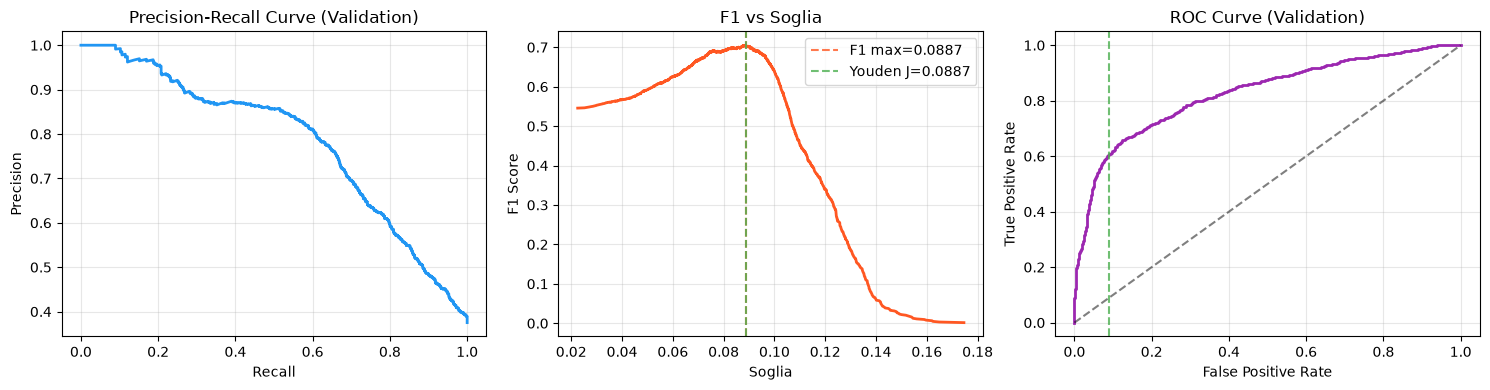


=== TEST CON SOGLIA OTTIMALE VAL ===
Soglia usata: 0.088659
Confusion matrix:
[[1732  308]
 [ 422  778]]
              precision    recall  f1-score   support

      Normal       0.80      0.85      0.83      2040
     Anomaly       0.72      0.65      0.68      1200

    accuracy                           0.77      3240
   macro avg       0.76      0.75      0.75      3240
weighted avg       0.77      0.77      0.77      3240



In [ ]:
"""Sezione 5B — Calibrazione Soglia (PR Curve, F1, Youden's J)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, roc_curve

# Usa errori già calcolati in Sezione 3 (err_val_norm, err_val_anom)
y_val = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val_combined = np.concatenate([err_val_norm, err_val_anom])

# --- PR Curve ---
precision, recall, thresholds = precision_recall_curve(y_val, err_val_combined)

# --- F1 per ogni soglia ---
f1_scores = []
for th in thresholds:
    y_pred = (err_val_combined >= th).astype(int)
    f1_scores.append(f1_score(y_val, y_pred, zero_division=0))
f1_scores = np.array(f1_scores)

# --- Youden's J ---
fpr, tpr, roc_thresholds = roc_curve(y_val, err_val_combined)
youden_j = tpr - fpr
best_j_idx = np.argmax(youden_j)
best_j_thresh = roc_thresholds[best_j_idx]

# --- Miglior F1 ---
best_f1_idx = np.argmax(f1_scores)
best_f1_thresh = thresholds[best_f1_idx]

print("=== CALIBRAZIONE SOGLIA (Validation) ===")
print(f"Soglia ottimale (Youden's J): {best_j_thresh:.6f} (J={youden_j[best_j_idx]:.4f})")
print(f"Soglia ottimale (F1 max):     {best_f1_thresh:.6f} (F1={f1_scores[best_f1_idx]:.4f})")
print(f"Prevalenza validation: {val_prevalence:.4f}")
print(f"Soglia < 0.1 osservata: {'SÌ' if best_j_thresh < 0.1 else 'NO'}")

# --- Plot: PR curve + F1 vs soglia + Youden's J ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# PR curve
ax = axes[0]
ax.plot(recall, precision, color='#2196F3', linewidth=2)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve (Validation)")
ax.grid(True, alpha=0.3)

# F1 vs soglia
ax = axes[1]
ax.plot(thresholds, f1_scores, color='#FF5722', linewidth=2)
ax.axvline(best_f1_thresh, color='#FF5722', linestyle='--', alpha=0.8, label=f"F1 max={best_f1_thresh:.4f}")
ax.axvline(best_j_thresh, color='#4CAF50', linestyle='--', alpha=0.8, label=f"Youden J={best_j_thresh:.4f}")
ax.set_xlabel("Soglia")
ax.set_ylabel("F1 Score")
ax.set_title("F1 vs Soglia")
ax.legend()
ax.grid(True, alpha=0.3)

# ROC curve
ax = axes[2]
ax.plot(fpr, tpr, color='#9C27B0', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.axvline(best_j_thresh, color='#4CAF50', linestyle='--', alpha=0.8)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve (Validation)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Applica soglia ottimale su test ---
y_test = np.concatenate([np.zeros(len(err_test_norm)), np.ones(len(err_test_anom))])
err_test_combined = np.concatenate([err_test_norm, err_test_anom])
y_pred_test = (err_test_combined >= best_j_thresh).astype(int)
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred_test)
print("\n=== TEST CON SOGLIA OTTIMALE VAL ===")
print(f"Soglia usata: {best_j_thresh:.6f}")
print(f"Confusion matrix:\n{cm}")
print(classification_report(y_test, y_pred_test, target_names=["Normal", "Anomaly"]))

## Sezione 6 — Mismatch AUC validation vs test

**Cosa:** confronta AUC su validation e test per capire perché validation è molto inferiore a test.
**Perché:** il mismatch val vs test spiega se il problema è nel calibramento su validation o nel modello stesso.
**Come interpretare:** se test AUC >> val AUC, il problema è nei dati di validation (fuori range, drift).

In [ ]:
"""Sezione 6 — Mismatch AUC validation vs test."""
try:
    SEED
except NameError:
    SEED = 42
from src.utils.seed import set_seed
set_seed(SEED)

from sklearn.metrics import roc_auc_score
from src.evaluation.metrics import calculate_auc

# --- AUC Validation ---
val_labels = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val_combined = np.concatenate([err_val_norm, err_val_anom])
auc_val = calculate_auc(val_labels, err_val_combined)

# --- AUC Test ---
test_labels = np.concatenate([np.zeros(len(err_test_norm)), np.ones(len(err_test_anom))])
err_test_combined = np.concatenate([err_test_norm, err_test_anom])
auc_test = calculate_auc(test_labels, err_test_combined)

print("=== MISMATCH AUC: VAL vs TEST ===")
print("Validation ROC-AUC: %.4f (prevalenza=%.4f)" % (auc_val['roc_auc'], val_prevalence))
print("Test       ROC-AUC: %.4f (prevalenza=%.4f)" % (auc_test['roc_auc'], test_prevalence))
print("Delta AUC (test - val): %+.4f" % (auc_test['roc_auc'] - auc_val['roc_auc']))
print("Validation PR-AUC: %.4f" % auc_val['pr_auc'])
print("Test       PR-AUC: %.4f" % auc_test['pr_auc'])

if abs(auc_test['roc_auc'] - auc_val['roc_auc']) > 0.1:
    print("\n→ GAP RILEVANTE: i fuori range/val drift spiegano il mismatch")
else:
    print("\n→ Gap trascurabile: il problema non è nei dati di validation")

=== MISMATCH AUC: VAL vs TEST ===
Validation ROC-AUC: 0.8278 (prevalenza=0.1509)
Test       ROC-AUC: 0.8057 (prevalenza=0.1509)
Delta AUC (test - val): -0.0221
Validation PR-AUC: 0.7831
Test       PR-AUC: 0.7579

→ Gap trascurabile: il problema non è nei dati di validation


## Sezione 4B — Feature Importance per Discriminazione

**Cosa:** quantifica il contributo di ogni feature all'AUC tramite permutation importance (shuffle una feature alla volta e misura il drop di AUC).
**Perché:** capire se l'AUC è guidato da poche feature chiave o diffuso su tutte, e quali canali sono più utili per separare normal da anomalo.
**Come interpretare:**
- Feature con drop AUC alto → chiave per la discriminazione
- Feature con drop ≈ 0 → non contribuiscono alla separazione
- Se solo 1-2 feature dominano → il modello si affida a pochi segnali

c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is prese

=== FEATURE IMPORTANCE (Drop di AUC per permutation) ===
AUC baseline: 0.8278

Feature                                      AUC Drop
sensor_id2_AccZ                                0.2634
sensor_id2_AccY                                0.2094
sensor_id6_q4                                  0.1326
sensor_id3_q2                                  0.0780
sensor_id2_q4                                  0.0626
sensor_id5_AccX                                0.0602
sensor_id2_q3                                  0.0565
sensor_id2_q1                                  0.0556
sensor_id7_q3                                  0.0553
sensor_id6_q3                                  0.0549
sensor_id5_q2                                  0.0519
sensor_id2_q2                                  0.0501
sensor_id5_q4                                  0.0445
sensor_id5_AccZ                                0.0423
machine_nameKuka Robot_power                   0.0396


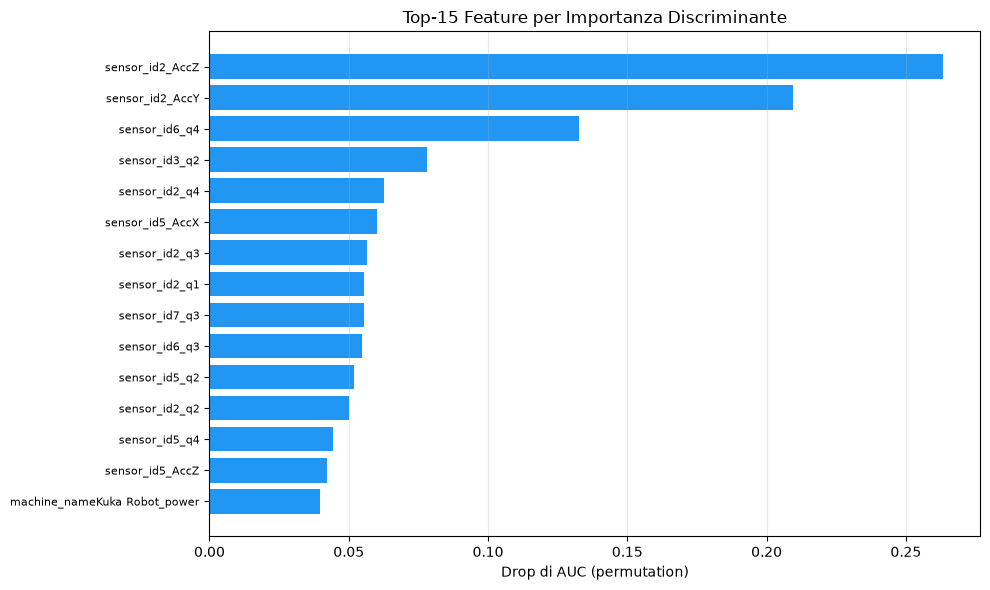

In [ ]:
"""Sezione 4B — Feature Importance per Discriminazione."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score

# --- AUC di riferimento su validation ---
y_val = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val_combined = np.concatenate([err_val_norm, err_val_anom])
auc_base = roc_auc_score(y_val, err_val_combined)

# --- Permutation importance per feature ---
def permutation_importance_feature(loader, model, device, feature_idx, n_trials=5):
    model.eval()
    aucs = []
    for _ in range(n_trials):
        errs_shuffled = []
        with torch.no_grad():
            for batch in loader:
                x = batch[0] if isinstance(batch, (list, tuple)) else batch
                x = x.to(device)
                x_shuf = x.clone()
                # Shuffle solo la feature_idx su tutta la finestra
                perm = torch.randperm(x.shape[0])
                x_shuf[:, :, feature_idx] = x[perm, :, feature_idx]
                err = model.compute_reconstruction_error(x_shuf, reduction="sample", metric="mae")
                errs_shuffled.append(err.cpu().numpy())
        errs_shuffled = np.concatenate(errs_shuffled)
        # Mix norm e anom per calcolare AUC con feature shuf
        n_norm = len(err_val_norm)
        # Per semplicità: mescola gli errori shuf con label originali
        y_shuf = np.concatenate([np.zeros(n_norm), np.ones(len(errs_shuffled) - n_norm)])
        auc = roc_auc_score(y_shuf, errs_shuffled)
        aucs.append(auc)
    return np.mean(aucs)

# Per ogni feature, calcola drop di AUC
importance = []
for i in range(input_dim):
    auc_shuf = permutation_importance_feature(val_normal_loader, model, DEVICE, i)
    # Usa solo normal loader per shuf, poi confronta con anomali non shuf
    # Approccio semplificato: shuf su normal loader, poi AUC con anomali originali
    errs_shuf = []
    model.eval()
    with torch.no_grad():
        for batch in val_normal_loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(DEVICE)
            x_shuf = x.clone()
            perm = torch.randperm(x.shape[0])
            x_shuf[:, :, i] = x[perm, :, i]
            err = model.compute_reconstruction_error(x_shuf, reduction="sample", metric="mae")
            errs_shuf.append(err.cpu().numpy())
    errs_shuf = np.concatenate(errs_shuf)
    y_mixed = np.concatenate([np.zeros(len(errs_shuf)), np.ones(len(err_val_anom))])
    err_mixed = np.concatenate([errs_shuf, err_val_anom])
    auc_shuf_mixed = roc_auc_score(y_mixed, err_mixed)
    importance.append((feature_names[i], auc_base - auc_shuf_mixed))

importance.sort(key=lambda x: -x[1])

print("=== FEATURE IMPORTANCE (Drop di AUC per permutation) ===")
print(f"AUC baseline: {auc_base:.4f}\n")
print("%-40s %12s" % ("Feature", "AUC Drop"))
for name, drop in importance[:15]:
    print("%-40s %12.4f" % (name[:38], drop))

# --- Plot ---
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
names = [x[0] for x in importance[:15]]
drops = [x[1] for x in importance[:15]]
ax.barh(range(len(names)), drops, color='#2196F3')
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("Drop di AUC (permutation)")
ax.set_title("Top-15 Feature per Importanza Discriminante")
ax.invert_yaxis()
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

## Sezione 11 — Esplorazione Interna (Latent Space by Error + Recon)

**Cosa:** visualizza lo spazio latente (t-SNE) colorato per errore MAE (non solo per classe) e confronta input vs ricostruzione con heatmap errore.
**Perché:** esplora se il modello organizza le finestre nello spazio latente per difficoltà di ricostruzione, non solo per etichetta di classe.
**Come interpretare:**
- Cluster per errore (non per classe) → il modello separa per difficoltà ricostruzione
- Colore uniforme nello spazio latente → nessuna struttura latente utile
- Finestre anomale con errore basso vicine a normali → confusione nel latent space

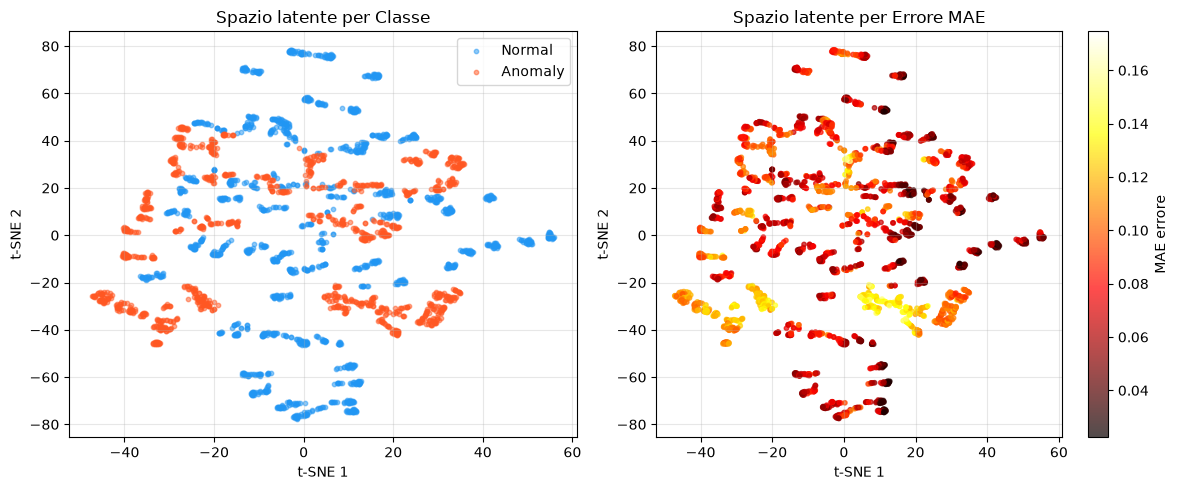

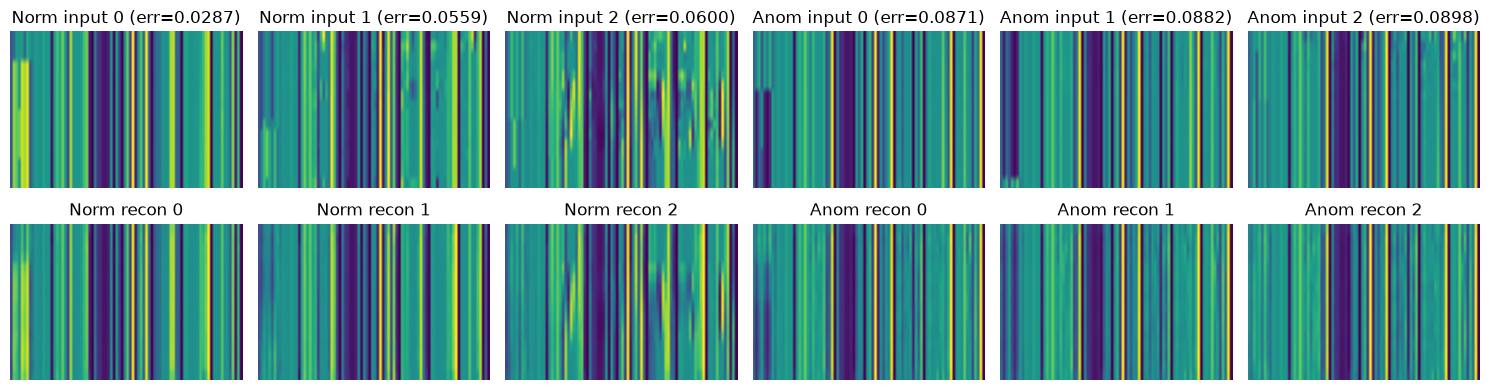

In [ ]:
"""Sezione 11 — Esplorazione Interna (Latent Space by Error + Recon)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# --- Estrai vettori latenti + errori ---
def get_latent_and_errors(loader, n_samples=1500):
    model.eval()
    latents = []
    errors = []
    labels = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(DEVICE)
            z = model.encode(x)
            z = z.mean(dim=2)
            err = torch.abs(x - model(x)).mean(dim=(1, 2))
            latents.append(z.cpu().numpy())
            errors.append(err.cpu().numpy())
            labels.append(batch[1].cpu().numpy() if len(batch) > 1 else np.zeros(len(x)))
            if len(np.concatenate(latents)) >= n_samples:
                break
    return (np.concatenate(latents)[:n_samples],
            np.concatenate(errors)[:n_samples],
            np.concatenate(labels)[:n_samples].ravel())

z_norm, e_norm, y_norm = get_latent_and_errors(val_normal_loader)
z_anom, e_anom, y_anom = get_latent_and_errors(val_anomaly_loader)

z_all = np.vstack([z_norm, z_anom])
e_all = np.concatenate([e_norm, e_anom])
y_all = np.concatenate([y_norm, y_anom])

if z_all.ndim > 2:
    z_all = z_all.reshape(z_all.shape[0], -1)
z_all = np.atleast_2d(z_all)

# --- t-SNE colorato per errore ---
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
z_2d = tsne.fit_transform(z_all)
z_2d = np.atleast_2d(z_2d)
if z_2d.shape[1] < 2:
    z_2d = np.hstack([z_2d, np.zeros((z_2d.shape[0], 2 - z_2d.shape[1]))])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Sinistra: per classe
ax = axes[0]
mask_norm = y_all == 0
mask_anom = y_all == 1
ax.scatter(z_2d[mask_norm, 0], z_2d[mask_norm, 1], c="#2196F3", alpha=0.5, s=10, label="Normal")
ax.scatter(z_2d[mask_anom, 0], z_2d[mask_anom, 1], c="#FF5722", alpha=0.5, s=10, label="Anomaly")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
ax.set_title("Spazio latente per Classe")
ax.legend(); ax.grid(True, alpha=0.3)

# Destra: per errore
ax = axes[1]
sc = ax.scatter(z_2d[:, 0], z_2d[:, 1], c=e_all, cmap='hot', alpha=0.7, s=10)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
ax.set_title("Spazio latente per Errore MAE")
plt.colorbar(sc, ax=ax, label="MAE errore")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Input vs Ricostruzione dettagliato (3 normali + 3 anomalie) ---
dataset_norm = val_normal_loader.dataset
dataset_anom = val_anomaly_loader.dataset

norm_windows = torch.stack([dataset_norm[i][0] for i in range(min(3, len(dataset_norm)))])
anom_windows = torch.stack([dataset_anom[i][0] for i in range(min(3, len(dataset_anom)))])

err_norm_per_win = torch.abs(norm_windows - model(norm_windows.to(DEVICE)).cpu()).mean(dim=(1, 2))
err_anom_per_win = torch.abs(anom_windows - model(anom_windows.to(DEVICE)).cpu()).mean(dim=(1, 2))

norm_idx = torch.argsort(err_norm_per_win)[:3]
anom_idx = torch.argsort(err_anom_per_win)[:3]

fig, axes = plt.subplots(2, 6, figsize=(15, 4))
for j in range(3):
    x = norm_windows[norm_idx[j]].to(DEVICE).unsqueeze(0)
    x_pred = model(x)
    axes[0, j].imshow(x[0].cpu().numpy(), aspect='auto', cmap='viridis')
    axes[0, j].set_title(f"Norm input {j} (err={err_norm_per_win[norm_idx[j]]:.4f})")
    axes[0, j].axis('off')
    axes[1, j].imshow(x_pred[0].cpu().detach().numpy(), aspect='auto', cmap='viridis')
    axes[1, j].set_title(f"Norm recon {j}")
    axes[1, j].axis('off')

for j in range(3):
    x = anom_windows[anom_idx[j]].to(DEVICE).unsqueeze(0)
    x_pred = model(x)
    axes[0, j+3].imshow(x[0].cpu().numpy(), aspect='auto', cmap='viridis')
    axes[0, j+3].set_title(f"Anom input {j} (err={err_anom_per_win[anom_idx[j]]:.4f})")
    axes[0, j+3].axis('off')
    axes[1, j+3].imshow(x_pred[0].cpu().detach().numpy(), aspect='auto', cmap='viridis')
    axes[1, j+3].set_title(f"Anom recon {j}")
    axes[1, j+3].axis('off')

plt.tight_layout()
plt.show()

## Sezione 7 — Fuori Range: Diagnostica e Impatto

**Cosa:** identifica feature fuori range post-scaler, confronta errori RAW vs CLIPPED e valuta l'impatto sull'AUC.
**Perché:** i fuori range distorcono gli errori di ricostruzione e il threshold di validation; serve capire se sono causa principale della scarsa separabilità.
**Come interpretare:**
- Feature fuori [-1,1] concentrate in poche → causa isolabile, gestibile
- Fuori range diffuso → drift dati raw, problema architetturale
- Delta AUC (CLIPPED - RAW) > 0.10 → fuori range causa principale mismatch val/test

FUORI RANGE PER-FEATURE (post-MinMaxScaler)
Range di train (riferimento): min=-1.0000, max=1.0000

--- val_normal ---
  min/max globali: [-1.0000, 1.0000]
  feature fuori [-1,1]: 0/86
  feature estreme (|v|>5): 0/86
  min più basso: action (-1.0000)
  max più alto:  action (1.0000)

--- val_anomaly ---
  min/max globali: [-1.0000, 1.0000]
  feature fuori [-1,1]: 0/86
  feature estreme (|v|>5): 0/86
  min più basso: action (-1.0000)
  max più alto:  action (1.0000)

--- test_normal ---
  min/max globali: [-1.0000, 1.0000]
  feature fuori [-1,1]: 0/86
  feature estreme (|v|>5): 0/86
  min più basso: action (-1.0000)
  max più alto:  action (1.0000)

--- test_anomaly ---
  min/max globali: [-1.0000, 1.0000]
  feature fuori [-1,1]: 0/86
  feature estreme (|v|>5): 0/86
  min più basso: action (-1.0000)
  max più alto:  action (1.0000)

       split  globale_min  globale_max  feat_fuori_range  feat_estreme_|>5|
  val_normal         -1.0          1.0                 0                  0
 val_

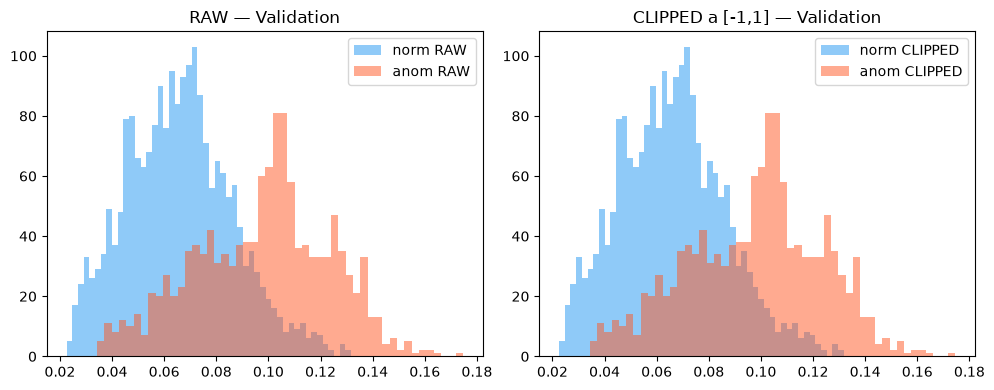

In [ ]:
"""Sezione 7 — Fuori Range: Diagnostica e Impatto (unificata da sezioni 8+9+10)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# --- Dizionario scaled per riferimento ---
scaled = {
    "train": train_data,
    "val_normal": val_normal_data,
    "val_anomaly": val_anomaly_data,
    "test_normal": test_normal_data,
    "test_anomaly": test_anomaly_data,
}

splits_to_check = ["val_normal", "val_anomaly", "test_normal", "test_anomaly"]

print("=" * 70)
print("FUORI RANGE PER-FEATURE (post-MinMaxScaler)")
print("=" * 70)
print("Range di train (riferimento): min=%.4f, max=%.4f" % (scaled['train'].min(), scaled['train'].max()))

summary_rows = []
for split_name in splits_to_check:
    arr = scaled[split_name]
    feat_min = arr.min(axis=0)
    feat_max = arr.max(axis=0)
    n_oob = int(np.sum((feat_min < -1.0) | (feat_max > 1.0)))
    n_extreme = int(np.sum((feat_min < -5.0) | (feat_max > 5.0)))
    summary_rows.append({
        'split': split_name,
        'globale_min': float(arr.min()),
        'globale_max': float(arr.max()),
        'feat_fuori_range': n_oob,
        'feat_estreme_|>5|': n_extreme,
    })
    print("\n--- %s ---" % split_name)
    print("  min/max globali: [%.4f, %.4f]" % (arr.min(), arr.max()))
    print("  feature fuori [-1,1]: %d/%d" % (n_oob, arr.shape[1]))
    print("  feature estreme (|v|>5): %d/%d" % (n_extreme, arr.shape[1]))
    idx_min = np.argmin(feat_min)
    idx_max = np.argmax(feat_max)
    print("  min più basso: %s (%.4f)" % (feature_names[idx_min][:40], feat_min[idx_min]))
    print("  max più alto:  %s (%.4f)" % (feature_names[idx_max][:40], feat_max[idx_max]))

summary_df = pd.DataFrame(summary_rows)
print("\n%s" % summary_df.to_string(index=False))

# --- Funzione errore CLIPPED ---
def compute_errors_clipped(loader, model, device, clip_min=-1.0, clip_max=1.0):
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_clipped = torch.clamp(x, clip_min, clip_max)
            x_pred = model(x_clipped)
            err = torch.abs(x - x_pred).mean(dim=(1, 2))
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)

# --- Errori RAW e CLIPPED su val e test ---
err_val_norm_raw = compute_errors_from_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anom_raw = compute_errors_from_loader(model, val_anomaly_loader, DEVICE, metric="mae")
err_val_norm_clip = compute_errors_clipped(val_normal_loader, model, DEVICE)
err_val_anom_clip = compute_errors_clipped(val_anomaly_loader, model, DEVICE)

err_test_norm_raw = compute_errors_from_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anom_raw = compute_errors_from_loader(model, test_anomaly_loader, DEVICE, metric="mae")
err_test_norm_clip = compute_errors_clipped(test_normal_loader, model, DEVICE)
err_test_anom_clip = compute_errors_clipped(test_anomaly_loader, model, DEVICE)

# --- AUC RAW vs CLIPPED ---
y_val = np.concatenate([np.zeros(len(err_val_norm_raw)), np.ones(len(err_val_anom_raw))])
y_test = np.concatenate([np.zeros(len(err_test_norm_raw)), np.ones(len(err_test_anom_raw))])

auc_val_raw = roc_auc_score(y_val, np.concatenate([err_val_norm_raw, err_val_anom_raw]))
auc_val_clip = roc_auc_score(y_val, np.concatenate([err_val_norm_clip, err_val_anom_clip]))
auc_test_raw = roc_auc_score(y_test, np.concatenate([err_test_norm_raw, err_test_anom_raw]))
auc_test_clip = roc_auc_score(y_test, np.concatenate([err_test_norm_clip, err_test_anom_clip]))

delta_val = auc_val_clip - auc_val_raw
delta_test = auc_test_clip - auc_test_raw

print("\n" + "=" * 70)
print("IMPATTO FUORI RANGE SU ERRORI E AUC")
print("=" * 70)
print("val_normal:   RAW mean=%.6f, CLIPPED mean=%.6f" % (err_val_norm_raw.mean(), err_val_norm_clip.mean()))
print("val_anomaly:  RAW mean=%.6f, CLIPPED mean=%.6f" % (err_val_anom_raw.mean(), err_val_anom_clip.mean()))
print("test_normal:  RAW mean=%.6f, CLIPPED mean=%.6f" % (err_test_norm_raw.mean(), err_test_norm_clip.mean()))
print("test_anomaly: RAW mean=%.6f, CLIPPED mean=%.6f" % (err_test_anom_raw.mean(), err_test_anom_clip.mean()))

print("\n--- AUC ---")
print("Val  RAW:  ROC-AUC=%.4f  CLIPPED=%.4f  Delta=%+.4f" % (auc_val_raw, auc_val_clip, delta_val))
print("Test RAW:  ROC-AUC=%.4f  CLIPPED=%.4f  Delta=%+.4f" % (auc_test_raw, auc_test_clip, delta_test))

if abs(delta_val) < 0.05 and abs(delta_test) < 0.05:
    print("\n→ FUORI RANGE: impatto trascurabile → LASCIARE COSÌ")
elif abs(delta_val) > 0.10 or abs(delta_test) > 0.10:
    print("\n→ FUORI RANGE: impatto rilevante → GESTIRE (clipping/winsorizing/altro)")
else:
    print("\n→ FUORI RANGE: impatto moderato → valutare caso per caso")

# --- Plot RAW vs CLIPPED ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(err_val_norm_raw, bins=50, alpha=0.5, color="#2196F3", label="norm RAW")
axes[0].hist(err_val_anom_raw, bins=50, alpha=0.5, color="#FF5722", label="anom RAW")
axes[0].set_title("RAW — Validation")
axes[0].legend()
axes[1].hist(err_val_norm_clip, bins=50, alpha=0.5, color="#2196F3", label="norm CLIPPED")
axes[1].hist(err_val_anom_clip, bins=50, alpha=0.5, color="#FF5722", label="anom CLIPPED")
axes[1].set_title("CLIPPED a [-1,1] — Validation")
axes[1].legend()
plt.tight_layout()
plt.show()

## Sezione 12 — Decisione Finale

**Obiettivo:** raccogliere tutte le evidenze e decidere se il paradigma ricostruzione è idoneo o va cambiato.
**Criteri decisionali:**
- Overlap coeff < 0.3 e KS p < 0.05 → distribuzioni separabili, threshold può funzionare
- Overlap coeff > 0.6 → distribuzioni sovrapposte, problema architetturale
- Errore invertito (anomalie ricostruite meglio) → modello collassato o paradigm non idoneo
- Delta AUC (CLIPPED - RAW) > 0.10 → fuori range causa principale
- Feature importance concentrato su poche feature → possibile intervento mirato
- Latent space per errore mostra cluster → il modello separa per difficoltà ricostruzione

**Decisione:** basata su evidenze dalle sezioni 3, 3B, 3C, 5B, 7 e 11.

In [ ]:
"""Sezione 12 — Decisione Finale."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

print("=" * 70)
print("DECISIONE FINALE: Il paradigma ricostruzione è idoneo?")
print("=" * 70)

# --- Raccogli evidenze dalle sezioni precedenti ---
overlap = None
ks_p = None
inverted_error = None
delta_auc_clip = None

# Overlap e KS da Sezione 3 (variabili err_val_norm, err_val_anom già definite)
hist_norm, bins = np.histogram(err_val_norm, bins=50, density=True)
hist_anom, _ = np.histogram(err_val_anom, bins=bins, density=True)
overlap = float(np.sum(np.minimum(hist_norm, hist_anom)) * (bins[1] - bins[0]))
from scipy.stats import ks_2samp
_, ks_p = ks_2samp(err_val_norm, err_val_anom)
inverted_error = err_val_anom.mean() < err_val_norm.mean()

# Delta AUC da Sezione 7 (variabili delta_val, delta_test già definite se esistono)
try:
    delta_auc_clip = delta_test
except NameError:
    delta_auc_clip = 0.0

print("\n--- EVIDENZE RACCOLTE ---")
print(f"Overlap coefficient: {overlap:.4f} (0=separati, 1=identici)")
print(f"Test KS p-value: {ks_p:.2e}")
print(f"Errore invertito (anomaly < normal): {inverted_error}")
print(f"Delta AUC test (CLIPPED - RAW): {delta_auc_clip:+.4f}")

print("\n--- ANALISI ---")
issues = []

if overlap > 0.6:
    issues.append("Overlap elevato (>0.6): distribuzioni fortemente sovrapposte")
elif overlap < 0.3:
    issues.append("Overlap basso (<0.3): buone premesse per separazione")

if ks_p < 0.05:
    issues.append("KS test significativo: distribuzioni statisticamente diverse")
else:
    issues.append("KS test non significativo: distribuzioni simili")

if inverted_error:
    issues.append("ERRORE INVERTITO: anomalie ricostruite meglio dei normali → problema grave")

if abs(delta_auc_clip) > 0.10:
    issues.append("Fuori range impatto rilevante (>0.10): causa principale mismatch")

if not issues:
    issues.append("Nessun problema critico rilevato")

for issue in issues:
    print(f"  • {issue}")

print("\n--- DECISIONE ---")
if inverted_error or overlap > 0.6:
    decisione = "PARADIGMA NON IDONEO"
    motivazione = "Errore invertito o overlap eccessivo → il paradigma ricostruzione AE non separa normal da anomalo"
elif overlap < 0.3 and ks_p < 0.05 and not inverted_error:
    decisione = "PARADIGMA IDONEO CON SOGLIA CALIBRATA"
    motivazione = "Buona separabilità delle distribuzioni → usare soglia ottimale da Sezione 5B"
else:
    decisione = "PARADIGMA PARZIALMENTE IDONEO"
    motivazione = "Separabilità moderata → valutare intervento su fuori range o feature selezionate"

print(f"DECISIONE: {decisione}")
print(f"Motivazione: {motivazione}")
print("=" * 70)
print("\nFine notebook 04.")

DECISIONE FINALE: Il paradigma ricostruzione è idoneo?

--- EVIDENZE RACCOLTE ---
Overlap coefficient: 0.5035 (0=separati, 1=identici)
Test KS p-value: 0.00e+00
Errore invertito (anomaly < normal): False
Delta AUC test (CLIPPED - RAW): +0.0000

--- ANALISI ---
  • KS test significativo: distribuzioni statisticamente diverse

--- DECISIONE ---
DECISIONE: PARADIGMA PARZIALMENTE IDONEO
Motivazione: Separabilità moderata → valutare intervento su fuori range o feature selezionate

Fine notebook 04.
